<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/02_type_classification_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Эксперимент B
Количество строк: 1025
Количество типов: 18


,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg
count,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00,1025.00
mean,70.18,77.52,72.51,70.08,70.21,67.19,1.21,66.99
std,26.63,29.78,29.29,29.66,26.64,28.72,1.25,121.27
min,1.00,5.00,5.00,10.00,20.00,5.00,0.10,0.10
25%,50.00,55.00,50.00,47.00,50.00,45.00,0.50,8.50
50%,68.00,75.00,70.00,65.00,67.00,65.00,1.00,28.00
75%,85.00,100.00,90.00,90.00,86.00,88.00,1.50,70.00
max,255.00,181.00,230.00,173.00,230.00,200.00,20.00,999.90



Распределение color:


,count
color,
blue,170
brown,147
green,130
gray,107
red,97
white,88
yellow,88
purple,87
pink,60


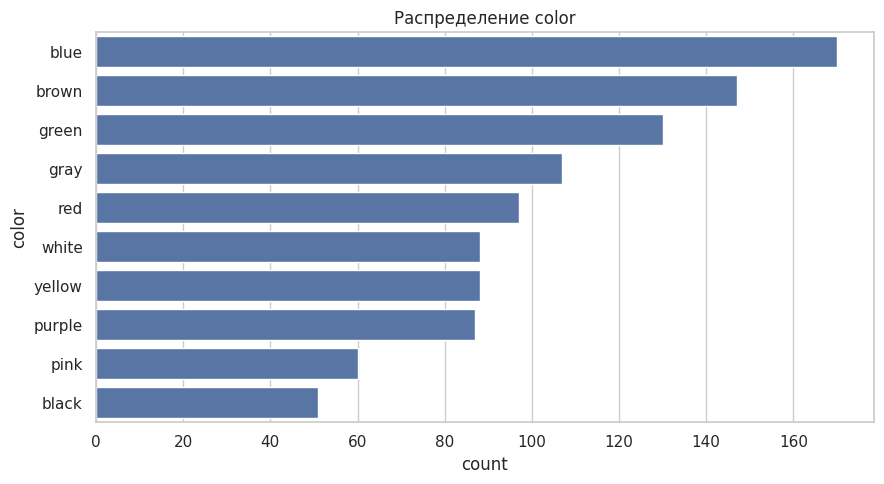


Распределение shape:


,count
shape,
upright,216
quadruped,200
humanoid,155
wings,87
ball,51
arms,48
fish,47
armor,46
blob,41


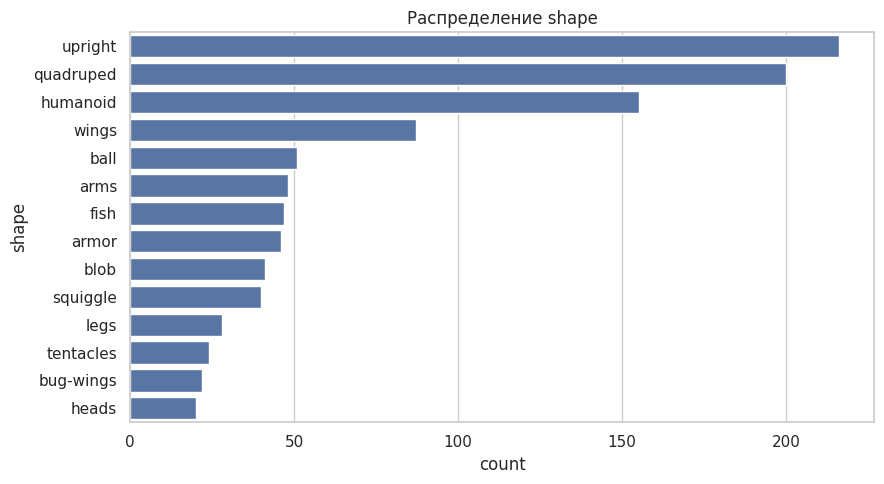


Количество объектов: color × type_1


type_1,Bug,Dark,Dragon,Electric,Fairy,Fighting,Fire,Flying,Ghost,Grass,Ground,Ice,Normal,Poison,Psychic,Rock,Steel,Water
color,,,,,,,,,,,,,,,,,,
black,2,11,1,4,0,0,0,0,10,0,2,0,6,6,4,3,1,1
blue,6,6,9,8,2,5,1,3,0,5,1,10,8,7,10,11,5,73
brown,5,7,1,0,1,8,13,0,7,11,15,3,42,3,4,17,4,6
gray,11,6,7,5,0,11,1,0,2,3,8,2,15,2,1,13,15,5
green,12,1,10,3,1,1,0,1,1,63,6,0,2,3,7,4,4,11
pink,0,2,1,1,12,0,0,1,0,5,0,1,16,0,10,1,1,9
purple,6,4,3,3,1,3,0,3,9,6,3,1,5,21,9,2,0,8
red,19,5,2,3,0,4,39,0,0,2,2,3,4,0,1,3,0,10
white,7,2,2,4,11,5,3,1,4,5,0,11,15,0,6,1,3,8



Количество объектов: shape × type_1


type_1,Bug,Dark,Dragon,Electric,Fairy,Fighting,Fire,Flying,Ghost,Grass,Ground,Ice,Normal,Poison,Psychic,Rock,Steel,Water
shape,,,,,,,,,,,,,,,,,,
armor,30,0,0,0,0,2,0,0,0,0,1,0,0,2,0,3,0,8
arms,3,0,1,4,5,0,0,1,10,3,3,1,1,4,6,2,2,2
ball,6,0,0,4,2,0,0,0,7,7,0,2,2,2,5,8,3,3
blob,4,1,0,0,1,0,0,0,6,8,2,2,0,3,2,2,3,7
bug-wings,18,0,0,0,0,0,1,0,0,0,1,1,0,1,0,0,0,0
fish,0,2,1,3,0,0,0,0,0,0,1,2,0,0,0,0,0,38
heads,1,0,0,1,0,1,0,0,0,4,1,1,2,1,0,3,5,0
humanoid,11,8,2,5,9,20,6,0,1,23,3,5,13,5,20,7,7,10
legs,0,0,0,0,1,0,1,0,0,8,1,0,5,0,2,4,2,4


In [ ]:
from pathlib import Path
import copy
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

SEED = 42

NUMERIC_FEATURES = [
    "hp", "attack", "defense",
    "sp_attack", "sp_defense", "speed",
    "height_m", "weight_kg",
]

CATEGORICAL_FEATURES = ["color", "shape"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

TARGET = "type_1"
GROUP = "evolution_chain_id"

PATH = Path("/content/drive/MyDrive/datasets/pokemon_complete.csv")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/classification_results_B"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_EPOCHS = 300
PATIENCE = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


if not PATH.is_file():
    raise FileNotFoundError(f"Файл не найден: {PATH}")

raw = pd.read_csv(PATH, encoding="utf-8-sig")

required = ["pokedex_number", "name", TARGET, GROUP, *FEATURES]
missing = set(required) - set(raw.columns)

if missing:
    raise ValueError(f"Отсутствуют столбцы: {sorted(missing)}")

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"], errors="raise"
)

# Тот же отбор, что и в эксперименте A.
df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy().reset_index(drop=True)

if df.empty:
    raise ValueError("После отбора выборка пуста")

if not df["pokedex_number"].is_unique:
    raise ValueError("Повторяются pokedex_number")

if df[[TARGET, GROUP]].isna().any().any():
    raise ValueError("Пропуски в target или evolution_chain_id")

df[TARGET] = df[TARGET].astype(str).str.strip()

if df[TARGET].eq("").any():
    raise ValueError("Пустые названия типов")

# Числовая проверка применяется только к числовым столбцам.
df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].apply(
    pd.to_numeric, errors="raise"
)

if df[NUMERIC_FEATURES].isna().any().any():
    raise ValueError("В числовых признаках появились пропуски")

if not np.isfinite(
    df[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Бесконечные значения признаков")

if (df[NUMERIC_FEATURES] < 0).any().any():
    raise ValueError("Отрицательные числовые характеристики")

# Не заполняем категории молча — проверяем качество данных.
for column in CATEGORICAL_FEATURES:
    if df[column].isna().any():
        raise ValueError(f"Пропуски в {column}")

    df[column] = df[column].astype(str).str.strip()

    if df[column].eq("").any():
        raise ValueError(f"Пустые категории в {column}")

print("Эксперимент B")
print("Количество строк:", len(df))
print("Количество типов:", df[TARGET].nunique())

display(df[NUMERIC_FEATURES].describe().round(2))

for column in CATEGORICAL_FEATURES:
    print(f"\nРаспределение {column}:")
    display(df[column].value_counts().to_frame("count"))

    plt.figure(figsize=(9, 5))
    sns.countplot(
        data=df,
        y=column,
        order=df[column].value_counts().index,
    )
    plt.title(f"Распределение {column}")
    save_plot(f"distribution_{column}.png")

# Эти таблицы описывают весь датасет.
# Не используем их для ручного подбора правил по test.
for column in CATEGORICAL_FEATURES:
    print(f"\nКоличество объектов: {column} × type_1")
    display(pd.crosstab(df[column], df[TARGET]))

In [ ]:
SPLIT_A_PATH = Path(
    "/content/drive/MyDrive/classification_results/split.csv"
)

if not SPLIT_A_PATH.is_file():
    raise FileNotFoundError(
        f"Не найден split эксперимента A: {SPLIT_A_PATH}\n"
        "Укажите фактический путь к сохранённому split.csv."
    )

split_a = pd.read_csv(SPLIT_A_PATH)

required_split_columns = ["pokedex_number", "split"]
missing = set(required_split_columns) - set(split_a.columns)

if missing:
    raise ValueError(
        f"В split.csv отсутствуют столбцы: {sorted(missing)}"
    )

if split_a[required_split_columns].isna().any().any():
    raise ValueError("В сохранённом разбиении есть пустые ID или split")

split_a["pokedex_number"] = pd.to_numeric(
    split_a["pokedex_number"],
    errors="raise",
)

split_a["split"] = split_a["split"].astype(str).str.strip()

if not split_a["pokedex_number"].is_unique:
    raise ValueError("В split.csv повторяются pokedex_number")

expected_names = {"train", "validation", "test"}

if set(split_a["split"]) != expected_names:
    raise ValueError(
        "Ожидались значения train, validation, test; "
        f"получены: {sorted(split_a['split'].unique())}"
    )

# Проверяем, что в A и B используется один набор объектов.
ids_A = set(split_a["pokedex_number"])
ids_B = set(df["pokedex_number"])

if ids_A != ids_B:
    print("Есть в A, но отсутствуют в B:", sorted(ids_A - ids_B)[:20])
    print("Есть в B, но отсутствуют в A:", sorted(ids_B - ids_A)[:20])

    raise ValueError(
        "Наборы покемонов A и B различаются. "
        "Проверьте версию CSV и отбор основных записей."
    )

# Проверяем неизменность target и групп, если они сохранены в A.
reference = split_a.set_index("pokedex_number")
current = df.set_index("pokedex_number")

for column in [TARGET, GROUP]:
    if column not in reference.columns:
        print(
            f"Предупреждение: {column} не сохранён в split A; "
            "проверка неизменности этого поля не выполнена."
        )
        continue

    old_values = reference[column].reindex(current.index)
    new_values = current[column]

    if column == GROUP:
        old_values = pd.to_numeric(old_values, errors="raise")
        new_values = pd.to_numeric(new_values, errors="raise")
    else:
        old_values = old_values.astype("string").str.strip()
        new_values = new_values.astype("string").str.strip()

    same = old_values.eq(new_values).fillna(False)

    if not same.all():
        changed_ids = current.index[~same].tolist()

        raise ValueError(
            f"Изменилось поле {column} у ID: {changed_ids[:20]}. "
            "Проверьте исходные данные."
        )

# Назначаем каждой строке ту же часть, что в эксперименте A.
split_by_id = reference["split"]
assigned_split = df["pokedex_number"].map(split_by_id)

train = df.loc[assigned_split == "train"].copy()
val = df.loc[assigned_split == "validation"].copy()
test = df.loc[assigned_split == "test"].copy()

parts = {
    "train": train,
    "validation": val,
    "test": test,
}

print("Разбиение загружено из эксперимента A:")
print(pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "chains": part[GROUP].nunique(),
    }
    for name, part in parts.items()
]).to_string(index=False))

parts = {
    "train": train,
    "validation": val,
    "test": test,
}

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    overlap = set(parts[first][GROUP]) & set(parts[second][GROUP])
    if overlap:
        raise ValueError(f"Пересечение цепочек: {first}/{second}")

all_ids = pd.concat([
    part["pokedex_number"] for part in parts.values()
])

if (
    not all_ids.is_unique
    or len(all_ids) != len(df)
    or set(all_ids) != set(df["pokedex_number"])
):
    raise ValueError("Некорректное разбиение строк")

unseen = (
    set(val[TARGET]) | set(test[TARGET])
) - set(train[TARGET])

if unseen:
    raise ValueError(f"В train отсутствуют типы: {sorted(unseen)}")

CLASSES = np.array(sorted(train[TARGET].unique()))

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "row_share": len(part) / len(df),
        "chains": part[GROUP].nunique(),
    }
    for name, part in parts.items()
])

counts = pd.DataFrame({
    name: part[TARGET].value_counts()
    for name, part in parts.items()
}).reindex(CLASSES).fillna(0).astype(int)

print("Размеры выборок:")
display(summary.round(3))

print("Представленность типов:")
display(counts)

split_table = pd.concat([
    part[["pokedex_number", GROUP, TARGET]].assign(split=name)
    for name, part in parts.items()
])

split_table.to_csv(
    OUTPUT_DIR / "split.csv",
    index=False,
    encoding="utf-8-sig",
)

summary.to_csv(OUTPUT_DIR / "split_sizes.csv", index=False)
counts.to_csv(OUTPUT_DIR / "type_counts.csv")


def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                NUMERIC_FEATURES,
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CATEGORICAL_FEATURES,
            ),
        ],
        sparse_threshold=0,
    )


def calculate_metrics(y_true, prediction):
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, prediction
        ),
        "macro_f1": f1_score(
            y_true,
            prediction,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true,
            prediction,
            average="weighted",
            zero_division=0,
        ),
    }


# Проверяем неизвестные категории на validation.
# Их OneHotEncoder обработает без ошибки.
for column in CATEGORICAL_FEATURES:
    unknown = set(val[column]) - set(train[column])
    print(f"Новые категории {column} в validation:", sorted(unknown))

Разбиение загружено из эксперимента A:
     split  rows  chains
     train   655     345
validation   170      87
      test   200     109
Размеры выборок:


,split,rows,row_share,chains
0,train,655,0.639,345
1,validation,170,0.166,87
2,test,200,0.195,109


Представленность типов:


,train,validation,test
type_1,,,
Bug,43,22,18
Dark,37,3,5
Dragon,25,5,7
Electric,33,17,9
Fairy,15,4,10
Fighting,24,6,10
Fire,34,18,14
Flying,7,2,0
Ghost,28,3,4


Новые категории color в validation: []
Новые категории shape в validation: []


In [ ]:
# Dummy не использует значения признаков, только частоты меток.
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(
    np.zeros((len(train), 1)),
    train[TARGET],
)

svm_models = {}
svm_rows = []

for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.01, 0.1]:
        for class_weight in [None, "balanced"]:
            candidate = make_pipeline(
                create_preprocessor(),
                SVC(
                    kernel="rbf",
                    C=C,
                    gamma=gamma,
                    class_weight=class_weight,
                ),
            )

            # И масштабирование, и категории обучаются только на train.
            candidate.fit(train[FEATURES], train[TARGET])
            prediction = candidate.predict(val[FEATURES])

            score = f1_score(
                val[TARGET],
                prediction,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )

            key = (float(C), str(gamma), str(class_weight))
            svm_models[key] = candidate

            svm_rows.append({
                "C": C,
                "gamma": str(gamma),
                "class_weight": str(class_weight),
                "validation_macro_f1": score,
            })

svm_results = pd.DataFrame(svm_rows).sort_values(
    "validation_macro_f1",
    ascending=False,
    kind="stable",
)

display(svm_results.round(4))

best_svm_row = svm_results.iloc[0]

best_key = (
    float(best_svm_row["C"]),
    best_svm_row["gamma"],
    best_svm_row["class_weight"],
)

svm = svm_models[best_key]

print("Выбранные параметры SVM:")
display(best_svm_row.to_frame("value"))

svm_results.to_csv(
    OUTPUT_DIR / "svm_validation_search.csv",
    index=False,
)

,C,gamma,class_weight,validation_macro_f1
15,10.0,0.01,balanced,0.2830
14,10.0,0.01,None,0.2715
11,1.0,0.1,balanced,0.2447
7,1.0,scale,balanced,0.2426
6,1.0,scale,None,0.2419
10,1.0,0.1,None,0.2419
13,10.0,scale,balanced,0.2401
17,10.0,0.1,balanced,0.2389
16,10.0,0.1,None,0.2325
12,10.0,scale,None,0.2315


Выбранные параметры SVM:


,value
C,10.0
gamma,0.01
class_weight,balanced
validation_macro_f1,0.283008


Входных признаков после кодирования: 32
Число классов: 18
Закодированные признаки:
['numeric__hp' 'numeric__attack' 'numeric__defense' 'numeric__sp_attack'
 'numeric__sp_defense' 'numeric__speed' 'numeric__height_m'
 'numeric__weight_kg' 'categorical__color_black' 'categorical__color_blue'
 'categorical__color_brown' 'categorical__color_gray'
 'categorical__color_green' 'categorical__color_pink'
 'categorical__color_purple' 'categorical__color_red'
 'categorical__color_white' 'categorical__color_yellow'
 'categorical__shape_armor' 'categorical__shape_arms'
 'categorical__shape_ball' 'categorical__shape_blob'
 'categorical__shape_bug-wings' 'categorical__shape_fish'
 'categorical__shape_heads' 'categorical__shape_humanoid'
 'categorical__shape_legs' 'categorical__shape_quadruped'
 'categorical__shape_squiggle' 'categorical__shape_tentacles'
 'categorical__shape_upright' 'categorical__shape_wings']
Epoch   1 | train loss=2.8656 | val loss=2.8502 | val macro-F1=0.0181
Epoch  20 | train lo

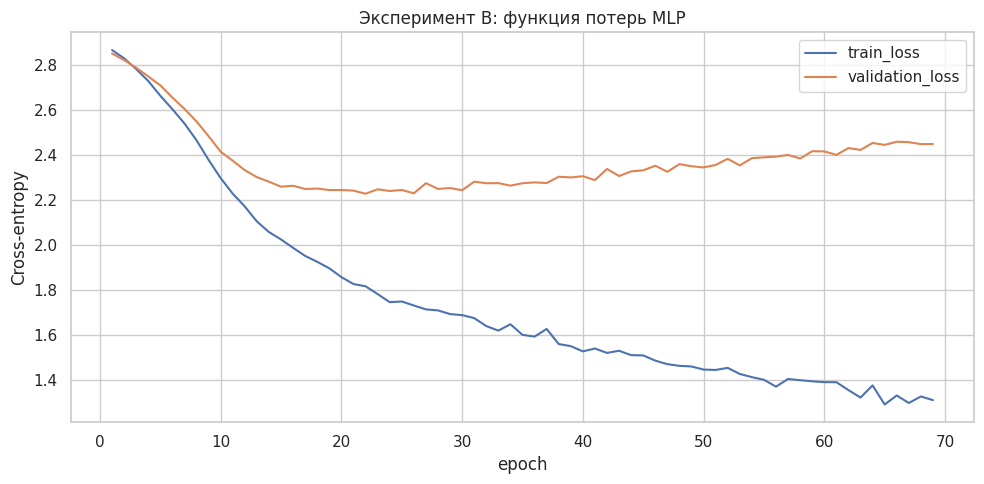

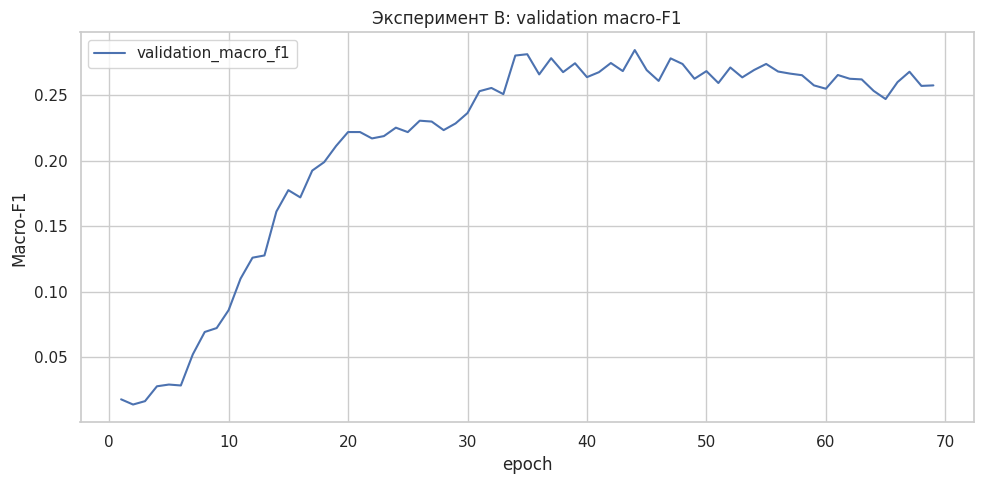

In [ ]:
# Восстанавливаем одинаковую начальную последовательность
# случайных чисел для воспроизводимости повторного запуска ячейки.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

nn_preprocessor = create_preprocessor()

X_train = nn_preprocessor.fit_transform(
    train[FEATURES]
).astype("float32")

X_val = nn_preprocessor.transform(
    val[FEATURES]
).astype("float32")

encoder = LabelEncoder()
y_train = encoder.fit_transform(train[TARGET])
y_val = encoder.transform(val[TARGET])

input_dim = X_train.shape[1]
num_classes = len(encoder.classes_)

print("Входных признаков после кодирования:", input_dim)
print("Число классов:", num_classes)
print("Закодированные признаки:")
print(nn_preprocessor.get_feature_names_out())

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.tensor(y_train, dtype=torch.long),
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
)

X_val_tensor = torch.from_numpy(X_val).to(DEVICE)
y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long,
    device=DEVICE,
)

mlp = nn.Sequential(
    nn.Linear(input_dim, 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, num_classes),
).to(DEVICE)

# Эксперимент B: обычная функция потерь, без весов классов.
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=LEARNING_RATE,
)

history_rows = []
best_val_score = -1.0
best_state = None
best_epoch = 0
waiting = 0

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.train()
    total_loss = 0.0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        logits = mlp(xb)

        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)

    mlp.eval()

    with torch.no_grad():
        val_logits = mlp(X_val_tensor)

        val_loss = criterion(
            val_logits, y_val_tensor
        ).item()

        predicted_ids = val_logits.argmax(dim=1).cpu().numpy()

    val_score = f1_score(
        y_val,
        predicted_ids,
        labels=np.arange(num_classes),
        average="macro",
        zero_division=0,
    )

    history_rows.append({
        "epoch": epoch,
        "train_loss": total_loss / len(train_dataset),
        "validation_loss": val_loss,
        "validation_macro_f1": val_score,
    })

    if val_score > best_val_score:
        best_val_score = val_score
        best_state = copy.deepcopy(mlp.state_dict())
        best_epoch = epoch
        waiting = 0
    else:
        waiting += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train loss={total_loss / len(train_dataset):.4f} | "
            f"val loss={val_loss:.4f} | "
            f"val macro-F1={val_score:.4f}"
        )

    if waiting >= PATIENCE:
        print(f"Ранняя остановка на эпохе {epoch}")
        break

mlp.load_state_dict(best_state)
mlp.eval()

print(
    f"Лучшая эпоха: {best_epoch}; "
    f"validation macro-F1: {best_val_score:.4f}"
)

history = pd.DataFrame(history_rows)
history.to_csv(OUTPUT_DIR / "mlp_history.csv", index=False)

history.plot(
    x="epoch",
    y=["train_loss", "validation_loss"],
    figsize=(10, 5),
)
plt.title("Эксперимент B: функция потерь MLP")
plt.ylabel("Cross-entropy")
save_plot("mlp_loss.png")

history.plot(
    x="epoch",
    y="validation_macro_f1",
    figsize=(10, 5),
)
plt.title("Эксперимент B: validation macro-F1")
plt.ylabel("Macro-F1")
save_plot("mlp_validation_f1.png")


def predict_mlp(part):
    X = nn_preprocessor.transform(
        part[FEATURES]
    ).astype("float32")

    mlp.eval()

    with torch.no_grad():
        logits = mlp(torch.from_numpy(X).to(DEVICE))
        predicted_ids = logits.argmax(dim=1).cpu().numpy()

    return encoder.inverse_transform(predicted_ids)


def predict_models(part):
    return {
        "Dummy": baseline.predict(np.zeros((len(part), 1))),
        "SVM RBF": svm.predict(part[FEATURES]),
        "PyTorch MLP": predict_mlp(part),
    }

In [ ]:
metric_rows = []
validation_predictions = None

for split_name, part in {
    "train": train,
    "validation": val,
}.items():
    predictions = predict_models(part)

    if split_name == "validation":
        validation_predictions = predictions

    for model_name, prediction in predictions.items():
        metric_rows.append({
            "split": split_name,
            "model": model_name,
            **calculate_metrics(part[TARGET], prediction),
        })

metrics_B = pd.DataFrame(metric_rows)

print("Эксперимент B: train и validation")
display(metrics_B.round(4))

metrics_B.to_csv(
    OUTPUT_DIR / "train_validation_metrics.csv",
    index=False,
)

# Фактические validation-метрики эксперимента A.
metrics_A = pd.DataFrame([
    {
        "model": "Dummy",
        "accuracy_A": 0.10588235294117647,
        "macro_f1_A": 0.010638297872340425,
    },
    {
        "model": "SVM RBF",
        "accuracy_A": 0.2235294117647059,
        "macro_f1_A": 0.17977300833271403,
    },
    {
        "model": "PyTorch MLP",
        "accuracy_A": 0.2,
        "macro_f1_A": 0.12618044902459277,
    },
])

validation_B = metrics_B.loc[
    metrics_B["split"] == "validation",
    ["model", "accuracy", "macro_f1"],
].rename(columns={
    "accuracy": "accuracy_B",
    "macro_f1": "macro_f1_B",
})

comparison = metrics_A.merge(validation_B, on="model")
comparison["accuracy_change"] = (
    comparison["accuracy_B"] - comparison["accuracy_A"]
)
comparison["macro_f1_change"] = (
    comparison["macro_f1_B"] - comparison["macro_f1_A"]
)

print("Сравнение A и B на validation:")
display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "comparison_A_B.csv",
    index=False,
)

# Выбираем рекомендуемую модель B только по validation.
candidates = metrics_B.loc[
    (metrics_B["split"] == "validation")
    & (metrics_B["model"] != "Dummy")
]

recommended_model = candidates.sort_values(
    "macro_f1",
    ascending=False,
    kind="stable",
).iloc[0]["model"]

print("Рекомендуемая модель B по validation:", recommended_model)

Эксперимент B: train и validation


,split,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,train,Dummy,0.1298,0.0556,0.0128,0.0298
1,train,SVM RBF,0.5405,0.5907,0.5294,0.5413
2,train,PyTorch MLP,0.5740,0.5089,0.5167,0.5462
3,validation,Dummy,0.1059,0.0556,0.0106,0.0203
4,validation,SVM RBF,0.3471,0.3106,0.2830,0.3790
5,validation,PyTorch MLP,0.4118,0.3324,0.2845,0.4115


Сравнение A и B на validation:


,model,accuracy_A,macro_f1_A,accuracy_B,macro_f1_B,accuracy_change,macro_f1_change
0,Dummy,0.1059,0.0106,0.1059,0.0106,0.0000,0.0000
1,SVM RBF,0.2235,0.1798,0.3471,0.2830,0.1235,0.1032
2,PyTorch MLP,0.2000,0.1262,0.4118,0.2845,0.2118,0.1583


Рекомендуемая модель B по validation: PyTorch MLP



validation: Dummy


,precision,recall,f1-score,support
Bug,0.000,0.0,0.000,22.0
Dark,0.000,0.0,0.000,3.0
Dragon,0.000,0.0,0.000,5.0
Electric,0.000,0.0,0.000,17.0
Fairy,0.000,0.0,0.000,4.0
Fighting,0.000,0.0,0.000,6.0
Fire,0.000,0.0,0.000,18.0
Flying,0.000,0.0,0.000,2.0
Ghost,0.000,0.0,0.000,3.0
Grass,0.000,0.0,0.000,21.0


Ошибок: 152 из 170


,pokedex_number,name,evolution_chain_id,type_1,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape,prediction,correct
22,23,Ekans,9,Poison,35,60,44,40,54,55,2.0,6.9,purple,squiggle,Water,False
23,24,Arbok,9,Poison,60,95,69,65,79,80,3.5,65.0,purple,squiggle,Water,False
42,43,Oddish,18,Grass,45,50,55,75,65,30,0.5,5.4,blue,legs,Water,False
43,44,Gloom,18,Grass,60,65,70,85,75,40,0.8,8.6,blue,humanoid,Water,False
44,45,Vileplume,18,Grass,75,80,85,110,90,50,1.2,18.6,red,humanoid,Water,False
47,48,Venonat,20,Bug,60,55,50,40,55,45,1.0,30.0,purple,humanoid,Water,False
48,49,Venomoth,20,Bug,70,65,60,90,75,90,1.5,12.5,purple,bug-wings,Water,False
65,66,Machop,28,Fighting,70,80,50,35,35,35,0.8,19.5,gray,upright,Water,False
66,67,Machoke,28,Fighting,80,100,70,50,60,45,1.5,70.5,gray,humanoid,Water,False
67,68,Machamp,28,Fighting,90,130,80,65,85,55,1.6,130.0,gray,humanoid,Water,False


Самые частые пары ошибок:


,,count
type_1,prediction,
Bug,Water,22
Grass,Water,21
Fire,Water,18
Electric,Water,17
Normal,Water,14
Poison,Water,11
Steel,Water,9
Rock,Water,7
Fighting,Water,6


... (8 outputs left out)

Ошибок: 100 из 170


,pokedex_number,name,evolution_chain_id,type_1,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape,prediction,correct
42,43,Oddish,18,Grass,45,50,55,75,65,30,0.5,5.4,blue,legs,Water,False
43,44,Gloom,18,Grass,60,65,70,85,75,40,0.8,8.6,blue,humanoid,Water,False
44,45,Vileplume,18,Grass,75,80,85,110,90,50,1.2,18.6,red,humanoid,Fire,False
47,48,Venonat,20,Bug,60,55,50,40,55,45,1.0,30.0,purple,humanoid,Poison,False
88,89,Muk,38,Poison,105,105,75,65,100,50,1.2,30.0,purple,arms,Ghost,False
99,100,Voltorb,44,Electric,40,30,50,55,55,100,0.5,10.4,red,ball,Bug,False
113,114,Tangela,52,Grass,65,55,115,100,40,60,1.0,35.0,blue,legs,Steel,False
144,145,Zapdos,74,Electric,90,90,85,125,90,100,1.6,52.6,yellow,wings,Psychic,False
164,165,Ledyba,84,Bug,40,20,30,40,80,55,1.0,10.8,red,wings,Normal,False
165,166,Ledian,84,Bug,55,35,50,55,110,85,1.4,35.6,red,wings,Normal,False


Самые частые пары ошибок:


,,count
type_1,prediction,
Electric,Psychic,5
Fire,Normal,5
Grass,Normal,5
Dragon,Fighting,3
Electric,Normal,3
Poison,Ghost,3
Steel,Ground,3
Grass,Water,3
Water,Psychic,3


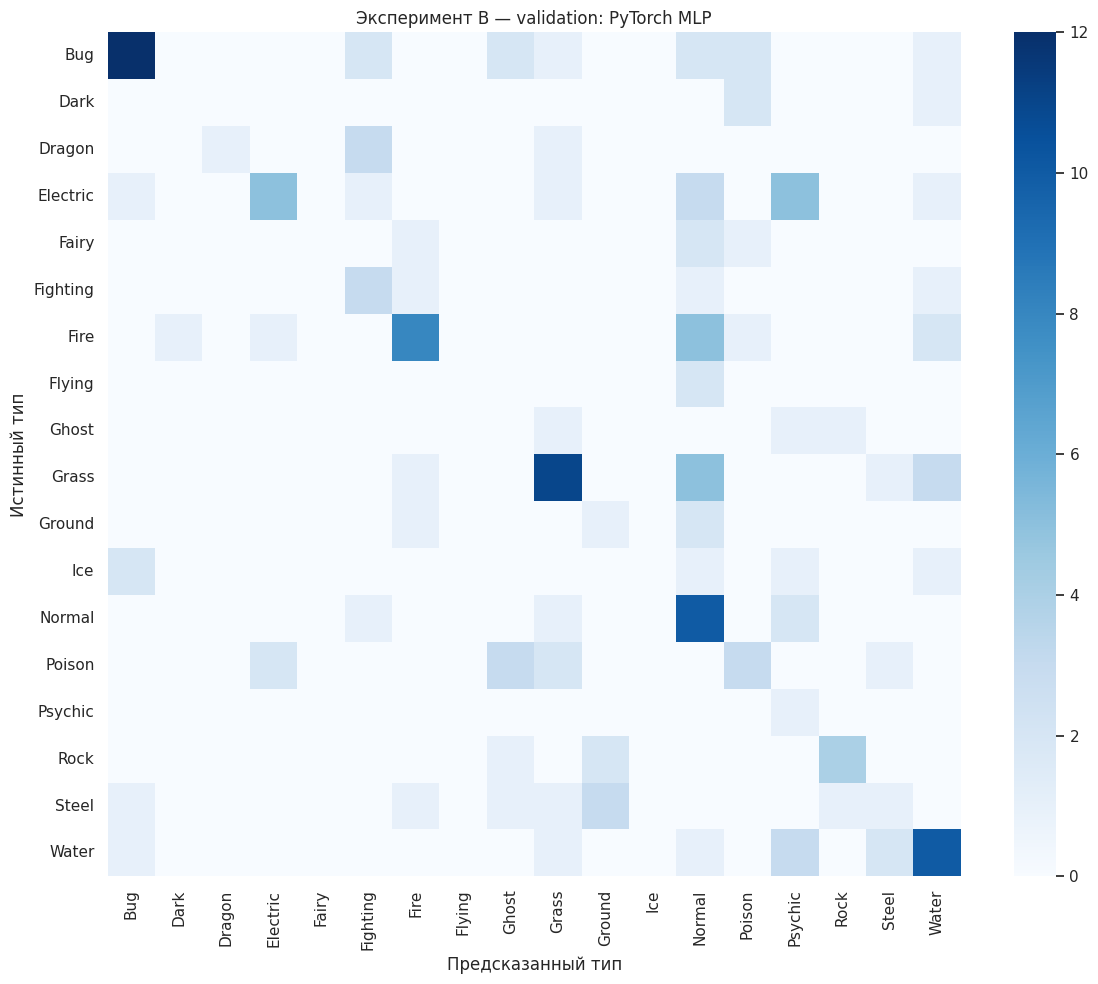

In [ ]:
def analyze_predictions(part, predictions, split_name):
    for model_name, prediction in predictions.items():
        safe_name = model_name.lower().replace(" ", "_")

        print("\n" + "=" * 60)
        print(f"{split_name}: {model_name}")

        report = pd.DataFrame(
            classification_report(
                part[TARGET],
                prediction,
                labels=CLASSES,
                output_dict=True,
                zero_division=0,
            )
        ).T

        display(
            report.loc[
                CLASSES,
                ["precision", "recall", "f1-score", "support"],
            ].round(3)
        )

        prediction_table = part[
            ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
        ].copy()

        prediction_table["prediction"] = prediction
        prediction_table["correct"] = (
            prediction_table[TARGET]
            == prediction_table["prediction"]
        )

        errors = prediction_table.loc[
            ~prediction_table["correct"]
        ]

        print(f"Ошибок: {len(errors)} из {len(part)}")
        display(errors.head(15))

        pairs = (
            errors.groupby([TARGET, "prediction"])
            .size()
            .sort_values(ascending=False)
            .rename("count")
        )

        print("Самые частые пары ошибок:")
        display(pairs.head(10).to_frame())

        prediction_table.to_csv(
            OUTPUT_DIR / f"{split_name}_{safe_name}_predictions.csv",
            index=False,
            encoding="utf-8-sig",
        )

        report.to_csv(
            OUTPUT_DIR / f"{split_name}_{safe_name}_report.csv",
            encoding="utf-8-sig",
        )


def plot_confusion(part, prediction, title, filename):
    matrix = confusion_matrix(
        part[TARGET],
        prediction,
        labels=CLASSES,
    )

    plt.figure(figsize=(12, 10))
    sns.heatmap(
        matrix,
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        cmap="Blues",
    )
    plt.title(title)
    plt.xlabel("Предсказанный тип")
    plt.ylabel("Истинный тип")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    save_plot(filename)


analyze_predictions(
    val,
    validation_predictions,
    "validation",
)

plot_confusion(
    val,
    validation_predictions[recommended_model],
    f"Эксперимент B — validation: {recommended_model}",
    "validation_confusion_matrix.png",
)

In [ ]:
joblib.dump(
    {
        "baseline": baseline,
        "svm": svm,
        "mlp_preprocessor": nn_preprocessor,
        "label_encoder": encoder,
        "numeric_features": NUMERIC_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "features": FEATURES,
        "target": TARGET,
        "recommended_model": recommended_model,
    },
    OUTPUT_DIR / "classification_models.joblib",
)

torch.save(
    {
        "state_dict": mlp.state_dict(),
        "input_dim": input_dim,
        "num_classes": num_classes,
        "classes": encoder.classes_.tolist(),
        "features": FEATURES,
        "best_epoch": best_epoch,
        "seed": SEED,
    },
    OUTPUT_DIR / "mlp_checkpoint.pt",
)

# Загружайте сохранённые модели только из доверенных источников.

RUN_TEST = False

if RUN_TEST:
    test_predictions = predict_models(test)

    test_results = pd.DataFrame([
        {
            "model": model_name,
            **calculate_metrics(test[TARGET], prediction),
        }
        for model_name, prediction in test_predictions.items()
    ])

    print("Финальная оценка B на test:")
    display(test_results.round(4))

    test_results.to_csv(
        OUTPUT_DIR / "test_metrics.csv",
        index=False,
    )

    analyze_predictions(test, test_predictions, "test")

    # Модель выбрана по validation, а не по test.
    plot_confusion(
        test,
        test_predictions[recommended_model],
        f"Эксперимент B — test: {recommended_model}",
        "test_confusion_matrix.png",
    )
else:
    print("Test не оценивался: сначала сравниваем A и B по validation.")

print("Результаты сохранены:", OUTPUT_DIR)

Test не оценивался: сначала сравниваем A и B по validation.
Результаты сохранены: /content/drive/MyDrive/classification_results_B
